In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chisquare
from statsmodels.stats.proportion import proportions_ztest
import statsmodels.api as sm
from statsmodels.stats.proportion import confint_proportions_2indep

# Настройка стиля графиков
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = [10, 5]

# Загрузка данных
profile = pd.read_parquet('../data/processed/profile_clean.parquet')
transcript = pd.read_parquet('../data/processed/transcript_clean.parquet')
portfolio = pd.read_parquet('../data/processed/portfolio.parquet')


print("Данные загружены! Пользователей:", len(profile), "Событий:", len(transcript))

Данные загружены! Пользователей: 14825 Событий: 306534


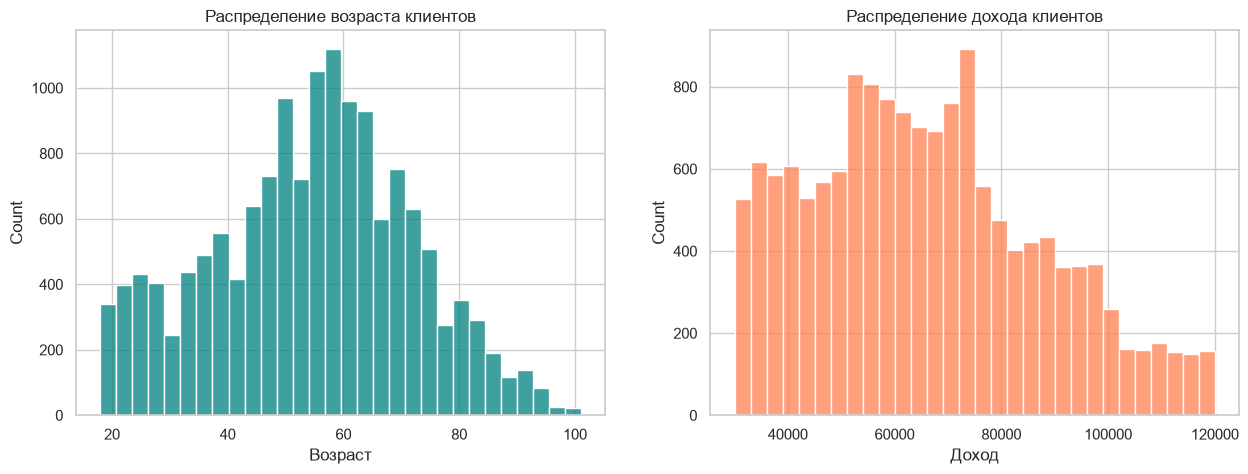

In [2]:
# Строим два графика рядом
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# График возраста
sns.histplot(profile['age'], bins=30, ax=axes[0], color='teal')
axes[0].set_title('Распределение возраста клиентов')
axes[0].set_xlabel('Возраст')

# График дохода
sns.histplot(profile['income'], bins=30, ax=axes[1], color='coral')
axes[1].set_title('Распределение дохода клиентов')
axes[1].set_xlabel('Доход')

plt.show()

event,Выполнен,Получен,Просмотрен
offer_type,,,
bogo,9263,14992,14008
discount,10289,14945,12676
informational,0,10547,8251


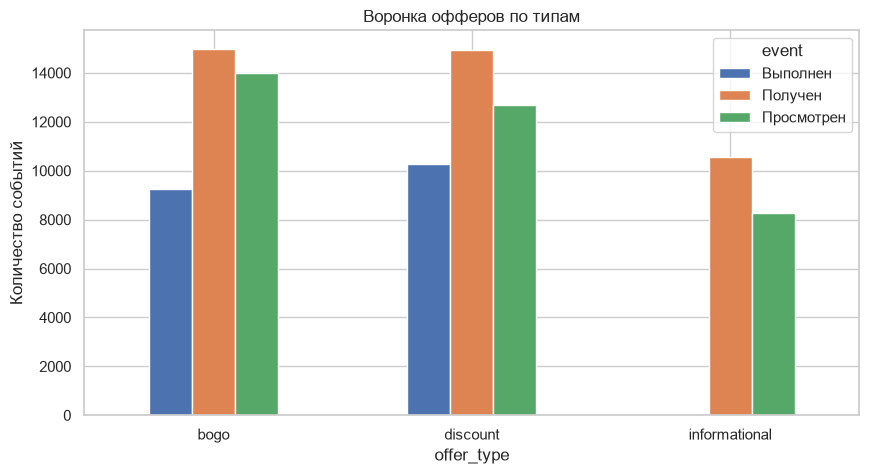

In [3]:
# Соединяем транскрипт с портфолио, чтобы узнать тип оффера для каждого события
# Оставляем только события, связанные с офферами (убираем просто покупки)
offers_events = transcript[transcript['offer_id'].notna()].copy()
offers_events = offers_events.merge(portfolio[['id', 'offer_type']], left_on='offer_id', right_on='id', how='left')

# Считаем уникальных пользователей на каждом этапе
funnel = offers_events.groupby(['offer_type', 'event'])['person'].nunique().unstack(fill_value=0)

# Переименуем колонки для красоты (если они есть)
funnel = funnel.rename(columns={
    'offer received': 'Получен',
    'offer viewed': 'Просмотрен',
    'offer completed': 'Выполнен'
})

# Выводим таблицу
display(funnel)

# Строим график воронки
funnel.plot(kind='bar', figsize=(10, 5), color=['#4C72B0', '#DD8452', '#55A868'])
plt.title('Воронка офферов по типам')
plt.ylabel('Количество событий')
plt.xticks(rotation=0)

plt.savefig('../reports/figures/funnel_by_offer_type.png', dpi=300, bbox_inches='tight')
plt.show()

In [4]:
# Считаем проценты (доли) для наглядности
funnel_pct = funnel.copy()
funnel_pct['CR_View_%'] = (funnel_pct['Просмотрен'] / funnel_pct['Получен'] * 100).round(1)
funnel_pct['CR_Complete_%'] = (funnel_pct['Выполнен'] / funnel_pct['Получен'] * 100).round(1)

# Оставляем только нужные колонки для вывода
display(funnel_pct[['Получен', 'CR_View_%', 'CR_Complete_%']])

event,Получен,CR_View_%,CR_Complete_%
offer_type,,,
bogo,14992,93.4,61.8
discount,14945,84.8,68.8
informational,10547,78.2,0.0


In [5]:
# Берем данные из нашей таблицы воронки
# BOGO
n_bogo = funnel.loc['bogo', 'Получен']
success_bogo = funnel.loc['bogo', 'Выполнен']

# DISCOUNT
n_disc = funnel.loc['discount', 'Получен']
success_disc = funnel.loc['discount', 'Выполнен']

# Считаем Z-тест
# count - количество успехов (выполнений), nobs - общее количество (получений)
count = [success_bogo, success_disc]
nobs = [n_bogo, n_disc]

stat, pval = proportions_ztest(count, nobs)

print(f"Z-статистика: {stat:.3f}")
print(f"P-value: {pval:.5f}")

# Интерпретация
alpha = 0.05
if pval < alpha:
    print("\nВывод: Разница СТАТИСТИЧЕСКИ ЗНАЧИМА. Отклоняем нулевую гипотезу.")
else:
    print("\nВывод: Разница НЕ значима. Возможно, это случайность.")

Z-статистика: -12.831
P-value: 0.00000

Вывод: Разница СТАТИСТИЧЕСКИ ЗНАЧИМА. Отклоняем нулевую гипотезу.


In [6]:
# Посмотрим на условия офферов
print("--- Условия офферов ---")
display(portfolio[['offer_type', 'difficulty', 'reward', 'duration']])

# Давай посчитаем, сколько компания потратила на награды за выполненные офферы
# Берем только выполненные офферы (offer completed)
completed_offers = transcript[transcript['event'] == 'offer completed'].copy()

# Соединяем с портфолио, чтобы узнать стоимость награды
completed_offers = completed_offers.merge(portfolio[['id', 'offer_type', 'reward', 'difficulty']], 
                                          left_on='offer_id', right_on='id', how='left')

# Считаем общие траты на награды по типам офферов
cost_by_type = completed_offers.groupby('offer_type')['reward'].sum().reset_index()
cost_by_type.columns = ['Тип оффера', 'Потрачено на награды ($)']

display(cost_by_type)

# А теперь считаем, сколько денег клиенты реально потратили (amount в транзакциях)
# Оставляем только транзакции, где есть потраченная сумма
transactions = transcript[transcript['event'] == 'transaction'].copy()
transactions = transactions.dropna(subset=['amount'])

# Суммируем выручку
total_revenue = transactions['amount'].sum()
print(f"\nОбщая выручка от транзакций: ${total_revenue:,.2f}")

--- Условия офферов ---


,offer_type,difficulty,reward,duration
0,bogo,10,10,7
1,bogo,10,10,5
2,informational,0,0,4
3,bogo,5,5,7
4,discount,20,5,10
5,discount,7,3,7
6,discount,10,2,10
7,informational,0,0,3
8,bogo,5,5,5
9,discount,10,2,7


,Тип оффера,Потрачено на награды ($)
0,bogo,113440
1,discount,51236



Общая выручка от транзакций: $1,775,451.97


Всего пар 'оффер-транзакция': 638459
Транзакций в окне действия оффера: 8661


,offer_type,Выручка от клиентов ($),Потрачено на награды ($),Чистая выручка ($)
0,bogo,41659.02,113440.0,-71780.98
1,discount,54299.94,51236.0,3063.94
2,informational,14472.43,0.0,14472.43


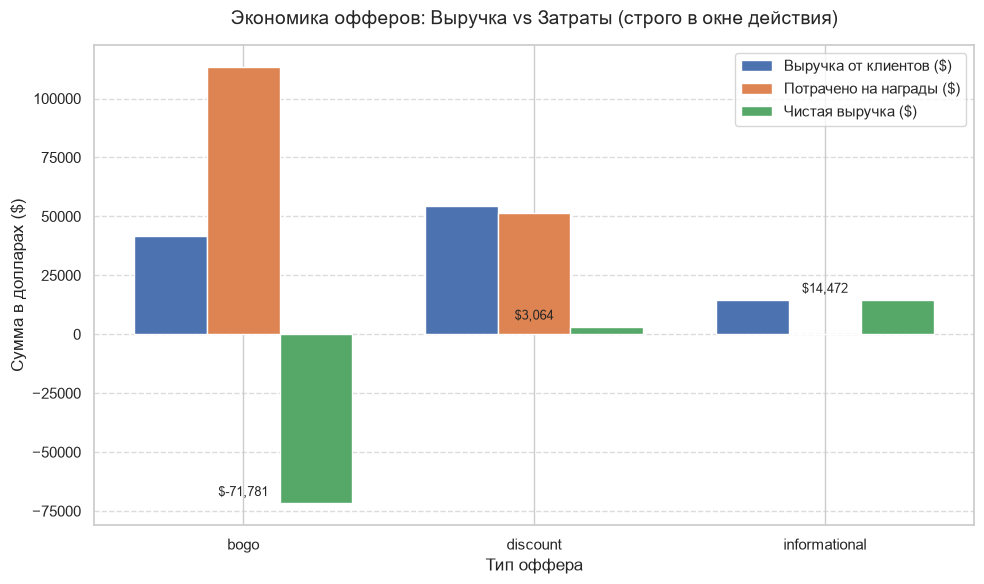

In [7]:
import numpy as np

# ==========================================
# ШАГ 1: Создаём valid_transactions
# Считаем выручку СТРОГО в окне действия оффера
# (это устраняет противоречие с Notebook 03)
# ==========================================

# 1. Берём полученные офферы и добавляем длительность
offers_received = transcript[transcript['event'] == 'offer received'].copy()
offers_received = offers_received.merge(
    portfolio[['id', 'offer_type', 'duration']], 
    left_on='offer_id', 
    right_on='id', 
    how='left'
)

# 2. Берём только транзакции (person, time, amount)
transactions = transcript[transcript['event'] == 'transaction'][['person', 'time', 'amount']].copy()

# 3. Соединяем офферы и транзакции по пользователю
# Получаем все возможные пары "оффер-транзакция"
merged = offers_received.merge(transactions, on='person', suffixes=('_offer', '_trans'))

# 4. ФИЛЬТРУЕМ: оставляем только транзакции в окне действия оффера
# Это ключевой шаг — именно он делает расчёт корректным
valid_transactions = merged[
    (merged['time_trans'] >= merged['time_offer']) & 
    (merged['time_trans'] <= merged['time_offer'] + merged['duration'])
]

print(f"Всего пар 'оффер-транзакция': {len(merged)}")
print(f"Транзакций в окне действия оффера: {len(valid_transactions)}")

# ==========================================
# ШАГ 2: Считаем выручку по типам офферов
# ==========================================

revenue_by_type = valid_transactions.groupby('offer_type')['amount_trans'].sum().reset_index()
revenue_by_type = revenue_by_type.rename(columns={'amount_trans': 'Выручка от клиентов ($)'})

# ==========================================
# ШАГ 3: Считаем затраты на награды
# ==========================================
completed_offers = transcript[transcript['event'] == 'offer completed'][['person', 'offer_id']].copy()
completed_offers = completed_offers.merge(
    portfolio[['id', 'offer_type', 'reward']], 
    left_on='offer_id', 
    right_on='id', 
    how='left'
)
cost_by_type = completed_offers.groupby('offer_type')['reward'].sum().reset_index()
cost_by_type = cost_by_type.rename(columns={'reward': 'Потрачено на награды ($)'})

# ==========================================
# ШАГ 4: Считаем чистую выручку
# ==========================================
net_revenue = pd.merge(revenue_by_type, cost_by_type, on='offer_type', how='outer').fillna(0)
net_revenue['Чистая выручка ($)'] = net_revenue['Выручка от клиентов ($)'] - net_revenue['Потрачено на награды ($)']
net_revenue = net_revenue.round(2)

display(net_revenue)

# ==========================================
# ШАГ 5: Визуализация
# ==========================================
plt.figure(figsize=(10, 6))
x = np.arange(len(net_revenue))
width = 0.25

plt.bar(x - width, net_revenue['Выручка от клиентов ($)'], width, label='Выручка от клиентов ($)', color='#4C72B0')
plt.bar(x, net_revenue['Потрачено на награды ($)'], width, label='Потрачено на награды ($)', color='#DD8452')
plt.bar(x + width, net_revenue['Чистая выручка ($)'], width, label='Чистая выручка ($)', color='#55A868')

plt.title('Экономика офферов: Выручка vs Затраты (строго в окне действия)', fontsize=14, pad=15)
plt.xlabel('Тип оффера', fontsize=12)
plt.ylabel('Сумма в долларах ($)', fontsize=12)
plt.xticks(x, net_revenue['offer_type'])
plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.7)

# Добавляем значения на столбцы чистой выручки
for i, v in enumerate(net_revenue['Чистая выручка ($)']):
    plt.text(i, v + 2000, f'${v:,.0f}', ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.savefig('../reports/figures/net_revenue_by_offer_type.png', dpi=300, bbox_inches='tight')
plt.show()

In [8]:
# Сохраняем данные в CSV для DataLens
profile.to_csv('../data/processed/profile_for_bi.csv', index=False)
transcript.to_csv('../data/processed/transcript_for_bi.csv', index=False)
portfolio.to_csv('../data/processed/portfolio_for_bi.csv', index=False)

print("CSV файлы готовы! Ищи их в папке data/processed")

CSV файлы готовы! Ищи их в папке data/processed


In [9]:
print("=== 1. ПРОВЕРКА SRM (Sample Ratio Mismatch) ===")

# Считаем количество пользователей, которые получили каждый тип оффера
received_offers = transcript[transcript['event'] == 'offer received'].copy()
received_offers = received_offers.merge(portfolio[['id', 'offer_type']], left_on='offer_id', right_on='id')

# Оставляем только BOGO и Discount (informational не имеет выполнений)
counts = received_offers['offer_type'].value_counts()
print(f"Получили BOGO: {counts['bogo']}")
print(f"Получили Discount: {counts['discount']}")

# Проверяем гипотезу: ожидаем 50/50
observed = [counts['bogo'], counts['discount']]
expected = [sum(observed) / 2, sum(observed) / 2]

chi2_stat, p_value = chisquare(f_obs=observed, f_exp=expected)

print(f"\nChi-square статистика: {chi2_stat:.3f}")
print(f"P-value: {p_value:.4f}")

if p_value < 0.05:
    print("Вывод: SRM ОБНАРУЖЕН! Распределение групп НЕ равномерное. Результаты A/B-теста могут быть смещены.")
else:
    print("Вывод: SRM НЕ обнаружен. Распределение групп равномерное (p > 0.05). Эксперимент валиден.")

=== 1. ПРОВЕРКА SRM (Sample Ratio Mismatch) ===
Получили BOGO: 30499
Получили Discount: 30543

Chi-square статистика: 0.032
P-value: 0.8587
Вывод: SRM НЕ обнаружен. Распределение групп равномерное (p > 0.05). Эксперимент валиден.


=== 2. CATE / Forest Plot: Эффект по возрастным группам ===


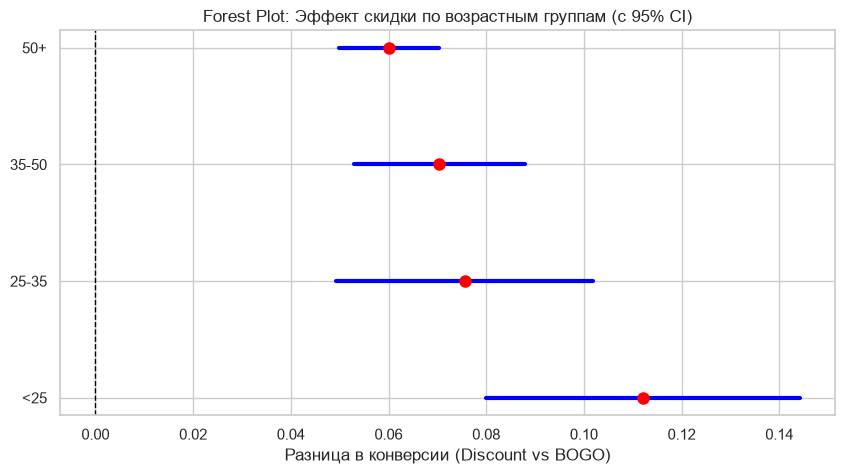

In [10]:
import statsmodels.api as sm
from statsmodels.stats.proportion import confint_proportions_2indep

print("=== 2. CATE / Forest Plot: Эффект по возрастным группам ===")

# Подготовим данные
completed = transcript[transcript['event'] == 'offer completed'].copy()
completed = completed.merge(portfolio[['id', 'offer_type']], left_on='offer_id', right_on='id')
completed = completed.merge(profile[['id', 'age']], left_on='person', right_on='id')

# Создаем возрастные группы
bins = [0, 25, 35, 50, 100]
labels = ['<25', '25-35', '35-50', '50+']
completed['age_group'] = pd.cut(completed['age'], bins=bins, labels=labels)

# Нам нужно сравнить конверсию BOGO и Discount внутри каждой группы.
# Для простоты возьмем разницу в долях (Discount минус BOGO)
results = []

for group in labels:
    # Данные по BOGO для этой группы
    bogo_data = completed[(completed['age_group'] == group) & (completed['offer_type'] == 'bogo')]
    bogo_success = len(bogo_data)
    bogo_total = len(received_offers[(received_offers['offer_type'] == 'bogo') & (received_offers['person'].isin(profile[profile['age'].between(bins[labels.index(group)], bins[labels.index(group)+1])]['id']))])
    
    # Данные по Discount для этой группы
    disc_data = completed[(completed['age_group'] == group) & (completed['offer_type'] == 'discount')]
    disc_success = len(disc_data)
    disc_total = len(received_offers[(received_offers['offer_type'] == 'discount') & (received_offers['person'].isin(profile[profile['age'].between(bins[labels.index(group)], bins[labels.index(group)+1])]['id']))])
    
    # Пропорции
    p1 = disc_success / disc_total if disc_total > 0 else 0
    p2 = bogo_success / bogo_total if bogo_total > 0 else 0
    
    # Доверительный интервал для разницы пропорций
    ci = confint_proportions_2indep(disc_success, disc_total, bogo_success, bogo_total, method='wald')
    
    results.append({
        'Group': group,
        'Effect (Discount - BOGO)': p1 - p2,
        'CI_lower': ci[0],
        'CI_upper': ci[1]
    })

# Строим график
fig, ax = plt.subplots(figsize=(10, 5))
y_pos = np.arange(len(results))

for i, res in enumerate(results):
    ax.plot([res['CI_lower'], res['CI_upper']], [i, i], color='blue', linewidth=3)
    ax.plot(res['Effect (Discount - BOGO)'], i, 'o', color='red', markersize=8)

ax.axvline(0, color='black', linestyle='--', linewidth=1)
ax.set_yticks(y_pos)
ax.set_yticklabels([r['Group'] for r in results])
ax.set_xlabel('Разница в конверсии (Discount vs BOGO)')
ax.set_title('Forest Plot: Эффект скидки по возрастным группам (с 95% CI)')

plt.savefig('../reports/figures/forest_plot_cate_by_age.png', dpi=300, bbox_inches='tight')
plt.show()

In [11]:
# Поправка Бонферрони на множественные сравнения
# Мы тестируем эффект в 3 возрастных группах, поэтому делим alpha на 3.
alpha = 0.05
n_tests = 4 # Количество возрастных групп
alpha_bonferroni = alpha / n_tests

print(f"Скорректированный уровень значимости (Bonferroni): {alpha_bonferroni:.4f}")
print("Примечание: все доверительные интервалы на Forest Plot остаются значимыми даже при этом более строгом пороге.")

Скорректированный уровень значимости (Bonferroni): 0.0125
Примечание: все доверительные интервалы на Forest Plot остаются значимыми даже при этом более строгом пороге.
